In [1]:
from argparse import ArgumentParser

from spacegraph_codebase.utils import *
from spacegraph_codebase.Place2Vec.cur_data_utils import load_pointset
from spacegraph_codebase.data_utils import load_ng
from spacegraph_codebase.model import NeighGraphEncoderDecoder
from spacegraph_codebase.train_helper import run_train, run_eval, run_joint_train
from spacegraph_codebase.trainer import *
from spacegraph_codebase.analyze_utils import *

from torch import optim
import numpy as np
import shlex
from spacegraph_codebase.trainer import make_args_parser, make_args_combine
parser = make_args_parser()
from pathlib import Path

import pandas as pd
import torch

# 各モデルを個別分析

In [2]:
exp_dir = Path("experiments_1028")
sh_file = exp_dir / "scripts" / "wl_1028_db4_scale_500_stg_1_sigma_0.5_lambda_0.5_seed_1.sh"
# exp_dir = Path("experiments_1027")
# sh_file = exp_dir / "scripts" / "theory_seed_1.sh"

with open(sh_file, "r") as f:
    command = f.read()

command = sh_file.read_text(encoding="utf-8")

# 行末の \ による改行を結合
command = command.replace("\\\n", " ")

# コメント・空行を除外し、単語に分割
tokens = shlex.split(command, comments=True)

# trainモジュールの位置を探す
module_name = "spacegraph_codebase.Place2Vec.train"

if module_name not in tokens:
    print(f"SKIP: {sh_file.name}")

start = tokens.index(module_name) + 1
args_list = tokens[start:]

args = parser.parse_args(args_list)


# モデル生成
g_enc_dec = make_enc_dec(args)
g_enc_dec.eval()


Create 3 FeedForward NN!!!!!!!!!!
WaveletMultisolSpatialRelationEncoder: input_embed_dim =  12021


/home/mine/卒業論文/WLemb/spacegraph/spacegraph_codebase/module.py:96: FutureWarning: `nn.init.xavier_uniform` is now deprecated in favor of `nn.init.xavier_uniform_`.
  nn.init.xavier_uniform(self.linear.weight)


create model from /Place2Vec_center-1-10-64-0.5-mean-global-0-1000.0-0.00-wlmultisol-64-32-40000.0-50.0-relu-geometric-T-T-500-db4--0.50-0.500000--1-512-T-T-T-concat-leakyrelu-sigmoid-1-T-T-concat-leakyrelu-sigmoid-1-T-T-max-sigmoid-adam-0.001000-512.pth


GlobalPositionEncoderDecoder(
  (enc): PointFeatureEncoder(
    (feat-embed): Embedding(1191, 64)
  )
  (g_spa_enc): WaveletMultisolSpatialRelationEncoder(
    (wlfunc): WLFuncForMultisol()
    (stg): StochasticGate()
    (ffn): MultiLayerFeedForwardNN(
      (layers): ModuleList(
        (0): SingleFeedForwardNN(
          (dropout): Dropout(p=0.5, inplace=False)
          (act): ReLU()
          (layernorm): LayerNorm((512,), eps=1e-05, elementwise_affine=True, bias=True)
          (linear): Linear(in_features=12021, out_features=512, bias=True)
        )
        (1): SingleFeedForwardNN(
          (dropout): Dropout(p=0.5, inplace=False)
          (act): ReLU()
          (linear): Linear(in_features=512, out_features=64, bias=True)
        )
      )
    )
  )
  (g_spa_dec): DirectPositionEmbeddingDecoder(
    (post_linear): Linear(in_features=64, out_features=64, bias=True)
    (dropout): Dropout(p=0.5, inplace=False)
    (f_act): Sigmoid()
  )
  (activation): Sigmoid()
)

In [3]:

# テスト用NeighborGraphを読み込む
test_ng_list = load_ng(
    str(Path(args.data_dir) / "neighborgraphs_test.pkl")
)

# モデル内のPointSetを取得
pointset = g_enc_dec.pointset

g_enc_dec.eval()

results = []
batch_size = 1000

with torch.no_grad():
    for start in range(0, len(test_ng_list), batch_size):
        batch = test_ng_list[start:start + batch_size]

        # 正例・負例の内積スコア
        pos, neg = g_enc_dec.get_batch_scores(
            batch,
            do_full_eval=True
        )

        pos = pos.detach().cpu().numpy()
        neg = neg.detach().cpu().numpy()

        # 元のget_batch_ranks()と同じ順位計算法
        scores = np.concatenate(
            [pos[:, None], neg], axis=1
        )

        ranks = (
            scores.shape[1]
            - np.argmin(np.argsort(scores, axis=1), axis=1)
        )

        for i, ng in enumerate(batch):
            point = pointset.pt_dict[ng.center_pt]
            rank = int(ranks[i])

            results.append({
                "point_id": ng.center_pt,
                "x": point.coord[0],
                "y": point.coord[1],
                "features": tuple(point.features),
                "rank": rank,
                "reciprocal_rank": 1.0 / rank,
                "hit1": int(rank <= 1),
                "hit5": int(rank <= 5),
                "hit10": int(rank <= 10),
                "pos_score": float(pos[i]),
                "neg_score_mean": float(neg[i].mean()),
                "neg_score_max": float(neg[i].max()),
                "score_margin": float(pos[i] - neg[i].max()),
                "num_neg": neg.shape[1],
            })

df_test = pd.DataFrame(results)

display(df_test.head())

,point_id,x,y,features,rank,reciprocal_rank,hit1,hit5,hit10,pos_score,neg_score_mean,neg_score_max,score_margin,num_neg
0,25044,-1.693191e+06,1.628682e+06,"(8, 8, 241)",12,0.083333,0,0,0,2.349798,-0.776606,3.087288,-0.737490,100
1,25198,-1.694501e+06,1.628859e+06,"(0, 15, 21)",22,0.045455,0,0,0,1.568847,-0.407189,2.955355,-1.386508,100
2,25339,-1.690408e+06,1.620209e+06,"(27, 27, 27)",57,0.017544,0,0,0,-1.003752,-0.817820,2.314331,-3.318083,100
3,25358,-1.704477e+06,1.631636e+06,"(4, 9, 171)",43,0.023256,0,0,0,-0.516771,-0.648715,2.475869,-2.992640,100
4,25333,-1.697078e+06,1.614788e+06,"(11, 32, 56)",40,0.025000,0,0,0,0.375046,-0.223867,2.623509,-2.248463,100


In [4]:
print(f"Test MRR:    {df_test['reciprocal_rank'].mean():.6f}")
print(f"Test HIT@1:  {df_test['hit1'].mean():.6f}")
print(f"Test HIT@5:  {df_test['hit5'].mean():.6f}")
print(f"Test HIT@10: {df_test['hit10'].mean():.6f}")

print(f"評価地点数: {len(df_test)}")
print(f"負例数: {df_test['num_neg'].unique()}")

Test MRR:    0.128707
Test HIT@1:  0.036830
Test HIT@5:  0.189744
Test HIT@10: 0.319347
評価地点数: 2145
負例数: [100]


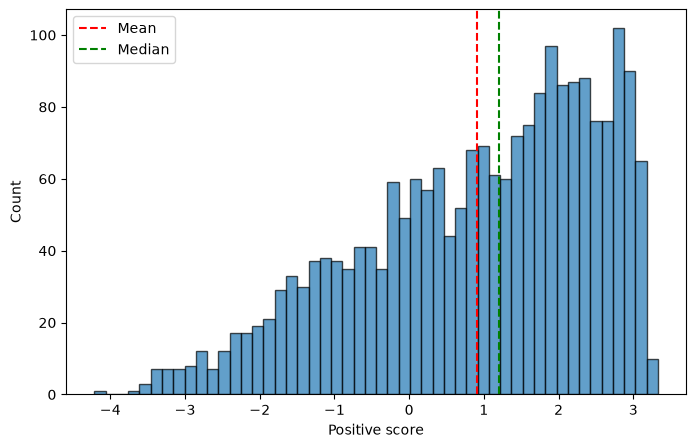

In [5]:
df_test["pos_score"].describe()

s = df_test["pos_score"]
fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(df_test["pos_score"], bins=50, edgecolor="black", alpha=0.7)
ax.axvline(s.mean(), color="red", linestyle="--", label="Mean")
ax.axvline(s.median(), color="green", linestyle="--", label="Median")

ax.set_xlabel("Positive score")
ax.set_ylabel("Count")
ax.legend()
plt.show()

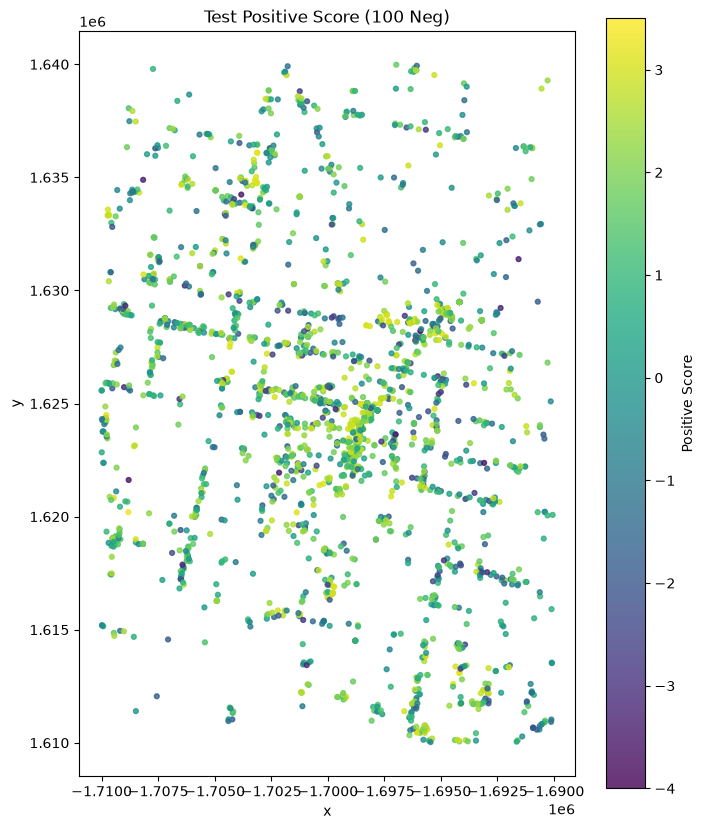

In [6]:
fig, ax = plt.subplots(figsize=(8, 10))

sc = ax.scatter(
    df_test["x"],
    df_test["y"],
    c=df_test["pos_score"],
    cmap="viridis",
    vmin=-4,
    vmax=3.5,
    s=12,
    alpha=0.8
)

ax.set_aspect("equal")
ax.set_title("Test Positive Score (100 Neg)")
ax.set_xlabel("x")
ax.set_ylabel("y")

plt.colorbar(sc, ax=ax, label="Positive Score")
plt.show()

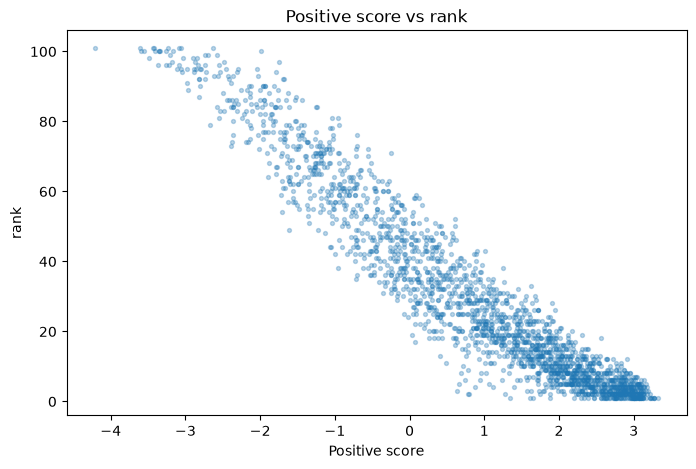

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(
    df_test["pos_score"],
    df_test["rank"],
    # df_test["reciprocal_rank"],
    s=8,
    alpha=0.3
)

ax.set_xlabel("Positive score")
ax.set_ylabel("rank")
# ax.set_ylabel("Reciprocal rank")
ax.set_title("Positive score vs rank")
# ax.set_title("Positive score vs Reciprocal rank")

plt.show()

In [8]:
df_test["score_bin"] = pd.qcut(
    df_test["pos_score"],
    q=10,
    duplicates="drop"
)

df_test.groupby(
    "score_bin",
    observed=True
).agg(
    count=("rank", "size"),
    mrr=("reciprocal_rank", "mean"),
    hit1=("hit1", "mean"),
    pos_score_mean=("pos_score", "mean")
)

,count,mrr,hit1,pos_score_mean
score_bin,,,,
"(-4.214, -1.435]",215,0.012381,0.000000,-2.175104
"(-1.435, -0.542]",214,0.016980,0.000000,-0.980177
"(-0.542, 0.0999]",215,0.024161,0.000000,-0.193182
"(0.0999, 0.696]",214,0.034979,0.000000,0.401261
"(0.696, 1.198]",215,0.052840,0.000000,0.958032
"(1.198, 1.676]",214,0.080289,0.014019,1.451645
"(1.676, 2.035]",214,0.105316,0.004673,1.860366
"(2.035, 2.4]",215,0.174216,0.018605,2.223754
"(2.4, 2.81]",214,0.323623,0.102804,2.611765


# モデル間比較

## 関数

In [33]:
def load_args_from_sh(sh_file):
    parser = make_args_parser()

    command = Path(sh_file).read_text(encoding="utf-8")
    command = command.replace("\\\n", " ")

    tokens = shlex.split(command, comments=True)

    module_name = "spacegraph_codebase.Place2Vec.train"
    start = tokens.index(module_name) + 1

    args = parser.parse_args(tokens[start:])

    return args


def evaluate_per_point(model, test_ng_list, batch_size=1000):

    model.eval()
    pointset = model.pointset

    results = []

    with torch.no_grad():
        for start in range(0, len(test_ng_list), batch_size):

            batch = test_ng_list[start:start + batch_size]

            pos, neg = model.get_batch_scores(
                batch,
                do_full_eval=True
            )

            pos = pos.detach().cpu().numpy()
            neg = neg.detach().cpu().numpy()

            scores = np.concatenate(
                [pos[:, None], neg],
                axis=1
            )

            # 既存のget_batch_ranks()と同じ計算
            ranks = (
                scores.shape[1]
                - np.argmin(np.argsort(scores, axis=1), axis=1)
            )

            for i, ng in enumerate(batch):

                point = pointset.pt_dict[ng.center_pt]
                rank = int(ranks[i])

                results.append({
                    "point_id": ng.center_pt,
                    "x": point.coord[0],
                    "y": point.coord[1],
                    "features": tuple(point.features),
                    "rank": rank,
                    "reciprocal_rank": 1.0 / rank,
                    "hit1": int(rank <= 1),
                    "hit5": int(rank <= 5),
                    "hit10": int(rank <= 10),
                    "pos_score": float(pos[i]),
                    "neg_score_mean": float(neg[i].mean()),
                    "neg_score_max": float(neg[i].max()),
                    "score_margin": float(
                        pos[i] - neg[i].max()
                    ),
                    "num_neg": neg.shape[1],
                })

    return pd.DataFrame(results)

## 比較

In [34]:
from pathlib import Path

exp_dir_1027 = Path("experiments_1027")
exp_dir_1028 = Path("experiments_1028")

models = {
    "theory": exp_dir_1027 / "scripts" / "theory_seed_2.sh",
    "wavelet_with_stg": exp_dir_1028 / "scripts" / "wl_1028_db4_scale_500_stg_1_sigma_0.5_lambda_0.5_seed_1.sh",
    "wavelet_without_stg": exp_dir_1027 / "scripts" / "wl_1022_db4_scale_500_stg_0_seed_1.sh",
}

In [35]:
from spacegraph_codebase.data_utils import load_ng

results_dict = {}

for model_name, sh_file in models.items():

    print(f"\n===== {model_name} =====")

    args = load_args_from_sh(sh_file)

    # モデル復元
    g_enc_dec = make_enc_dec(args)
    g_enc_dec.eval()

    # テストデータ
    test_ng_list = load_ng(
        str(Path(args.data_dir) / "neighborgraphs_test.pkl")
    )

    # 地点別評価
    df = evaluate_per_point(g_enc_dec, test_ng_list)

    results_dict[model_name] = df

    print(f"MRR: {df['reciprocal_rank'].mean():.6f}")
    print(f"HIT@1: {df['hit1'].mean():.6f}")
    print(f"HIT@5: {df['hit5'].mean():.6f}")
    print(f"HIT@10: {df['hit10'].mean():.6f}")


===== theory =====
Create 3 FeedForward NN!!!!!!!!!!
create model from /Place2Vec_center-2-10-64-0.5-mean-global-0-1000.0-0.00-theory-64-32-40000.0-50.0-relu-geometric-T-T-NoGate--1-512-T-T-T-concat-leakyrelu-sigmoid-1-T-T-concat-leakyrelu-sigmoid-1-T-T-max-sigmoid-adam-0.001000-512.pth


/home/mine/卒業論文/WLemb/spacegraph/spacegraph_codebase/module.py:96: FutureWarning: `nn.init.xavier_uniform` is now deprecated in favor of `nn.init.xavier_uniform_`.
  nn.init.xavier_uniform(self.linear.weight)


MRR: 0.138131
HIT@1: 0.049417
HIT@5: 0.194406
HIT@10: 0.324942

===== wavelet_with_stg =====
Create 3 FeedForward NN!!!!!!!!!!
WaveletMultisolSpatialRelationEncoder: input_embed_dim =  12021
create model from /Place2Vec_center-1-10-64-0.5-mean-global-0-1000.0-0.00-wlmultisol-64-32-40000.0-50.0-relu-geometric-T-T-500-db4--0.50-0.500000--1-512-T-T-T-concat-leakyrelu-sigmoid-1-T-T-concat-leakyrelu-sigmoid-1-T-T-max-sigmoid-adam-0.001000-512.pth
MRR: 0.128707
HIT@1: 0.036830
HIT@5: 0.189744
HIT@10: 0.319347

===== wavelet_without_stg =====
Create 3 FeedForward NN!!!!!!!!!!
WaveletMultisolSpatialRelationEncoder: input_embed_dim =  12021
create model from /Place2Vec_center-1-10-64-0.5-mean-global-0-1000.0-0.00-wlmultisol-64-32-40000.0-50.0-relu-geometric-T-T-500-db4-NoGate--1-512-T-T-T-concat-leakyrelu-sigmoid-1-T-T-concat-leakyrelu-sigmoid-1-T-T-max-sigmoid-adam-0.001000-512.pth
MRR: 0.136599
HIT@1: 0.048485
HIT@5: 0.192075
HIT@10: 0.321678


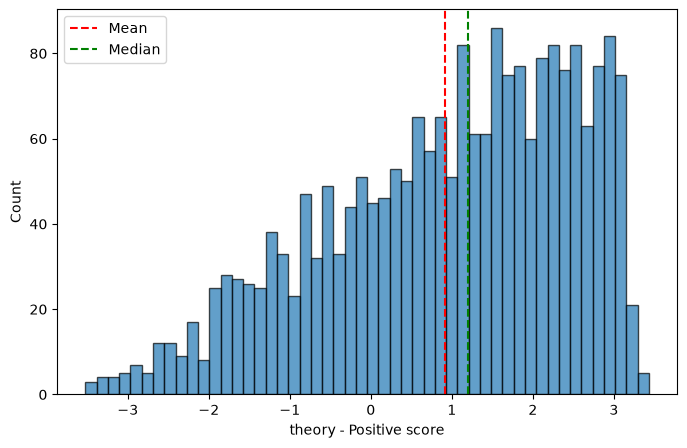

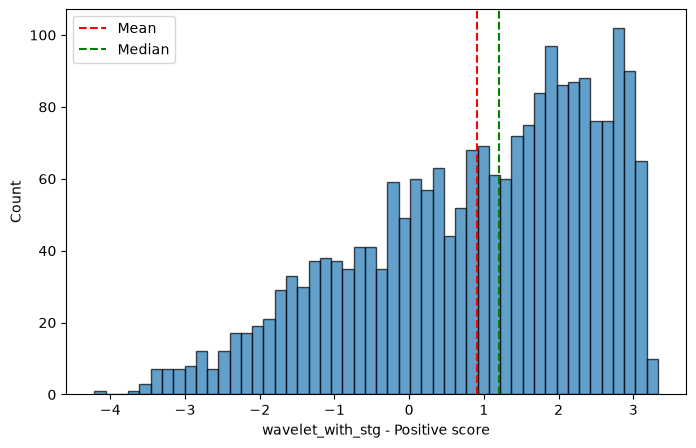

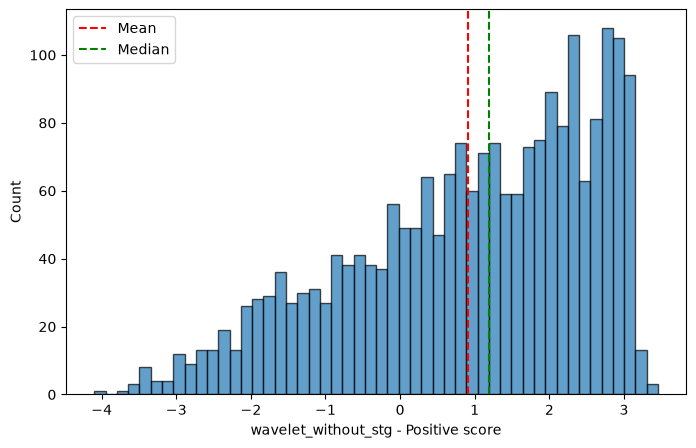

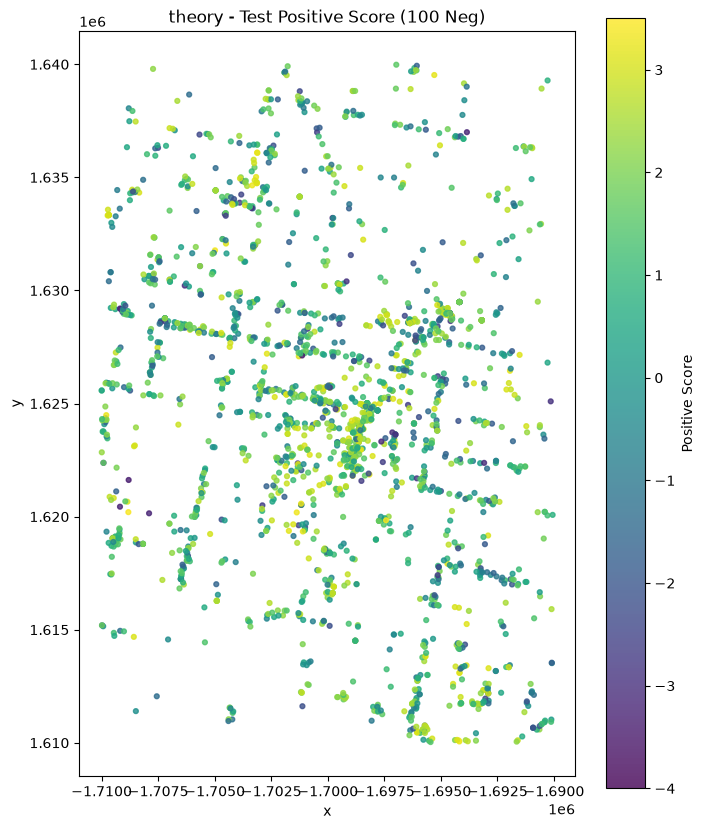

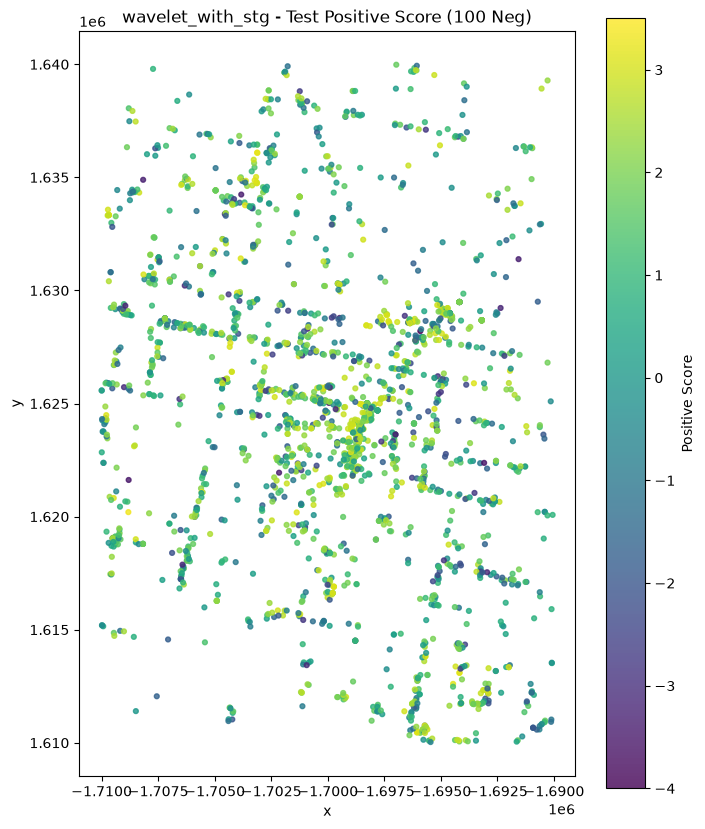

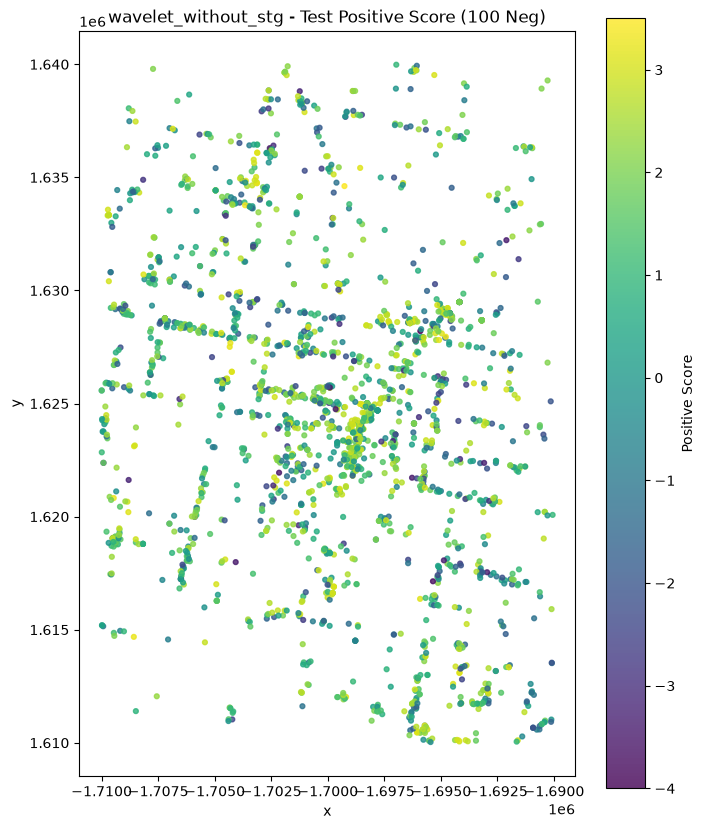

In [36]:
for model_name in results_dict.keys():
    df = results_dict[model_name]

    fig, ax = plt.subplots(figsize=(8, 5))

    ax.hist(df["pos_score"], bins=50, edgecolor="black", alpha=0.7)
    ax.axvline(s.mean(), color="red", linestyle="--", label="Mean")
    ax.axvline(s.median(), color="green", linestyle="--", label="Median")

    ax.set_xlabel(model_name + " - Positive score")
    ax.set_ylabel("Count")
    ax.legend()
    plt.show()

for model_name in results_dict.keys():
    df = results_dict[model_name]
    fig, ax = plt.subplots(figsize=(8, 10))

    sc = ax.scatter(
        df["x"],
        df["y"],
        c=df["pos_score"],
        cmap="viridis",
        vmin=-4,
        vmax=3.5,
        s=12,
        alpha=0.8
    )

    ax.set_aspect("equal")
    ax.set_title(model_name + " - Test Positive Score (100 Neg)")
    ax.set_xlabel("x")
    ax.set_ylabel("y")

    plt.colorbar(sc, ax=ax, label="Positive Score")
    plt.show()
    


In [37]:
summary = pd.DataFrame({
    name: {
        "MRR": df["reciprocal_rank"].mean(),
        "HIT@1": df["hit1"].mean(),
        "HIT@5": df["hit5"].mean(),
        "HIT@10": df["hit10"].mean(),
        "pos_score_mean": df["pos_score"].mean(),
        "pos_score_std": df["pos_score"].std(),
    }
    for name, df in results_dict.items()
}).T

display(summary)

,MRR,HIT@1,HIT@5,HIT@10,pos_score_mean,pos_score_std
theory,0.138131,0.049417,0.194406,0.324942,0.952961,1.543087
wavelet_with_stg,0.128707,0.036830,0.189744,0.319347,0.913872,1.589910
wavelet_without_stg,0.136599,0.048485,0.192075,0.321678,0.935461,1.626563


In [38]:
# base_name = "theory"
base_name = "wavelet_without_stg"
target_name = "wavelet_with_stg"
# target_name = "wavelet_without_stg"

In [39]:


df_base = results_dict[base_name]
df_target = results_dict[target_name]

df_compare = df_base.merge(
    df_target,
    on="point_id",
    how="inner",
    suffixes=(f"_{base_name}", f"_{target_name}"),
    validate="one_to_one"
)

assert len(df_compare) == len(df_base) == len(df_target)
assert np.allclose(df_compare[f"x_{base_name}"], df_compare[f"x_{target_name}"])
assert np.allclose(df_compare[f"y_{base_name}"], df_compare[f"y_{target_name}"])

# 比較に使う座標
df_compare["x"] = df_compare[f"x_{base_name}"]
df_compare["y"] = df_compare[f"y_{base_name}"]

# Wavelet - Theory
df_compare["delta_rr"] = (
    df_compare[f"reciprocal_rank_{target_name}"]
    - df_compare[f"reciprocal_rank_{base_name}"]
)

df_compare["delta_rank"] = (
    df_compare[f"rank_{base_name}"]
    - df_compare[f"rank_{target_name}"]
)

df_compare["delta_pos_score"] = (
    df_compare[f"pos_score_{target_name}"]
    - df_compare[f"pos_score_{base_name}"]
)

display(df_compare.head())

,point_id,x_wavelet_without_stg,y_wavelet_without_stg,features_wavelet_without_stg,rank_wavelet_without_stg,reciprocal_rank_wavelet_without_stg,hit1_wavelet_without_stg,hit5_wavelet_without_stg,hit10_wavelet_without_stg,pos_score_wavelet_without_stg,...,pos_score_wavelet_with_stg,neg_score_mean_wavelet_with_stg,neg_score_max_wavelet_with_stg,score_margin_wavelet_with_stg,num_neg_wavelet_with_stg,x,y,delta_rr,delta_rank,delta_pos_score
0,25044,-1.693191e+06,1.628682e+06,"(8, 8, 241)",7,0.142857,0,0,1,2.032691,...,2.349798,-0.776606,3.087288,-0.737490,100,-1.693191e+06,1.628682e+06,-0.059524,-5,0.317107
1,25198,-1.694501e+06,1.628859e+06,"(0, 15, 21)",29,0.034483,0,0,0,1.274859,...,1.568847,-0.407189,2.955355,-1.386508,100,-1.694501e+06,1.628859e+06,0.010972,7,0.293988
2,25339,-1.690408e+06,1.620209e+06,"(27, 27, 27)",4,0.250000,0,1,1,2.117961,...,-1.003752,-0.817820,2.314331,-3.318083,100,-1.690408e+06,1.620209e+06,-0.232456,-53,-3.121712
3,25358,-1.704477e+06,1.631636e+06,"(4, 9, 171)",26,0.038462,0,0,0,0.744725,...,-0.516771,-0.648715,2.475869,-2.992640,100,-1.704477e+06,1.631636e+06,-0.015206,-17,-1.261496
4,25333,-1.697078e+06,1.614788e+06,"(11, 32, 56)",63,0.015873,0,0,0,-0.706495,...,0.375046,-0.223867,2.623509,-2.248463,100,-1.697078e+06,1.614788e+06,0.009127,23,1.081542


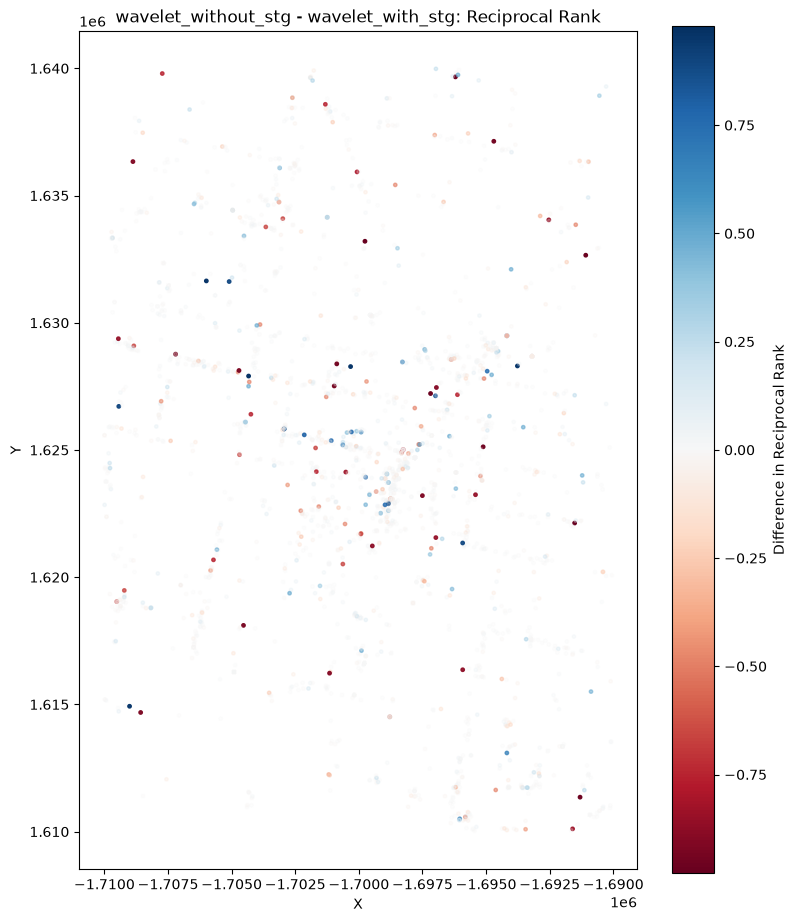

In [40]:
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

fig, ax = plt.subplots(figsize=(9, 11))

vmax = max(
    np.abs(df_compare["delta_rr"]).max(),
    1e-8
)

delta = df_compare["delta_rr"].to_numpy()
alpha_values = 0.2 + 0.8 * (np.abs(delta) / vmax)

sc = ax.scatter(
    df_compare["x"],
    df_compare["y"],
    c=df_compare["delta_rr"],
    cmap="RdBu",
    norm=TwoSlopeNorm(
        vmin=-vmax,
        vcenter=0,
        vmax=vmax
    ),
    s=6,
    alpha=alpha_values
)

ax.set_aspect("equal")
ax.set_title(f"{base_name} - {target_name}: Reciprocal Rank")
ax.set_xlabel("X")
ax.set_ylabel("Y")

plt.colorbar(
    sc,
    ax=ax,
    label="Difference in Reciprocal Rank"
)

plt.show()

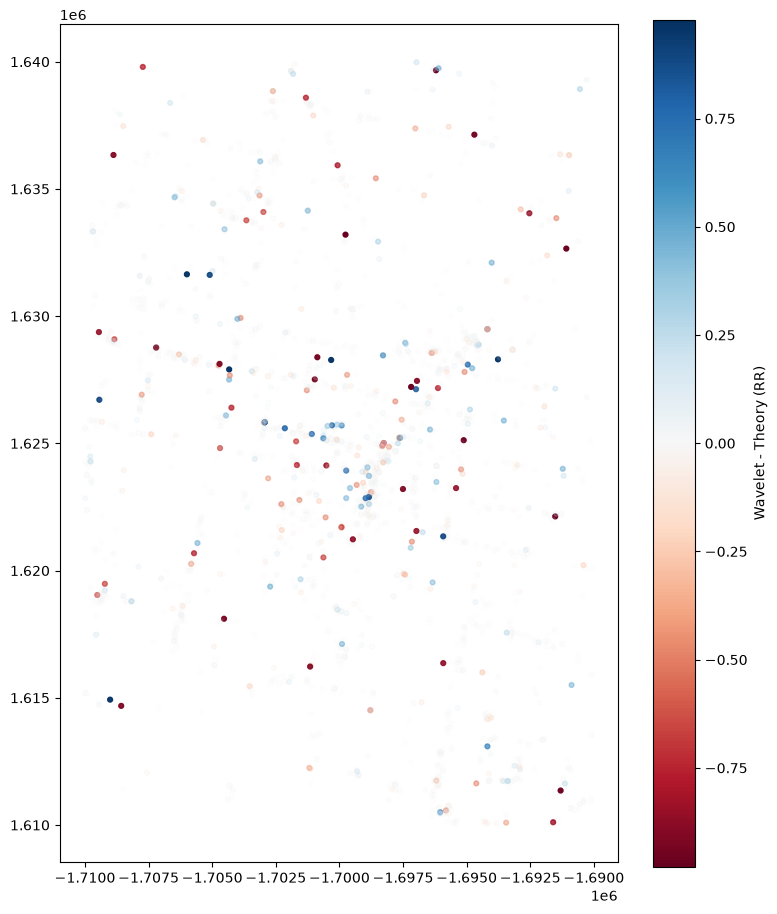

In [41]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

delta = df_compare["delta_rr"].to_numpy()

vmax = np.max(np.abs(delta))

# 色は正負を区別
norm = TwoSlopeNorm(
    vmin=-vmax,
    vcenter=0,
    vmax=vmax
)

# 透明度は差の絶対値に応じて変更
alpha_values = 0.05 + 0.95 * (np.abs(delta) / vmax)

fig, ax = plt.subplots(figsize=(9, 11))

sc = ax.scatter(
    df_compare["x"],
    df_compare["y"],
    c=delta,
    cmap="RdBu",
    norm=norm,
    s=12,
    alpha=alpha_values
)

ax.set_aspect("equal")
plt.colorbar(sc, ax=ax, label="Wavelet - Theory (RR)")
plt.show()

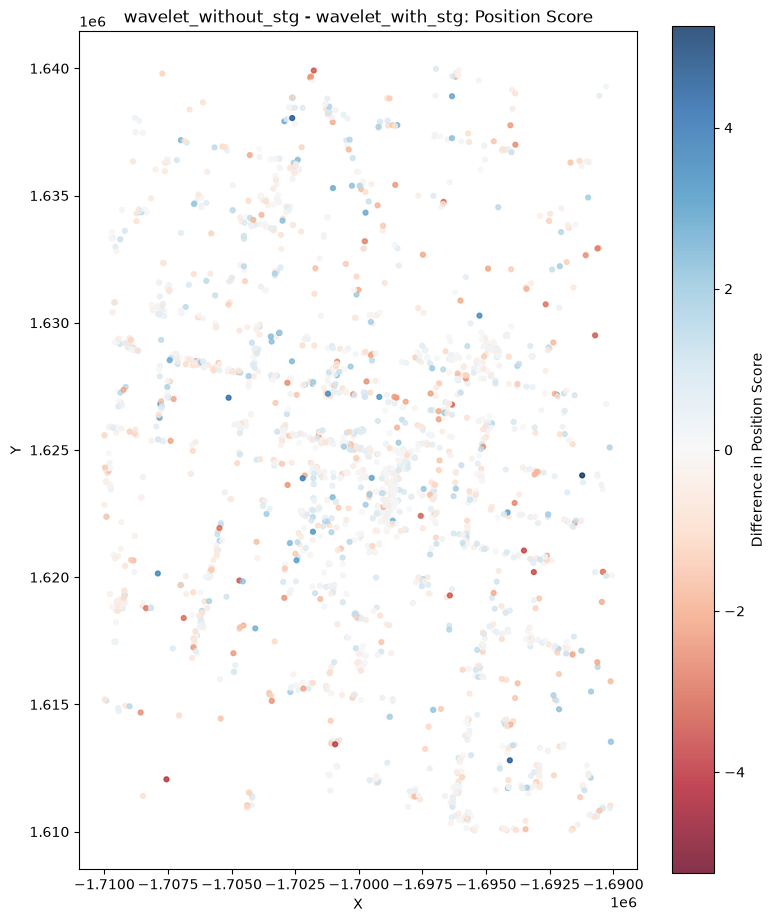

In [42]:
fig, ax = plt.subplots(figsize=(9, 11))

vmax = max(
    np.abs(df_compare["delta_pos_score"]).max(),
    1e-8
)

sc = ax.scatter(
    df_compare["x"],
    df_compare["y"],
    c=df_compare["delta_pos_score"],
    cmap="RdBu",
    norm=TwoSlopeNorm(
        vmin=-vmax,
        vcenter=0,
        vmax=vmax
    ),
    s=12,
    alpha=0.8
)

ax.set_aspect("equal")
ax.set_title(f"{base_name} - {target_name}: Position Score")
ax.set_xlabel("X")
ax.set_ylabel("Y")

plt.colorbar(
    sc,
    ax=ax,
    label="Difference in Position Score"
)

plt.show()

In [43]:
delta = df_compare["delta_rr"]

print(f"{target_name} 優位:", (delta > 0).sum())
print(f"{base_name} 優位:", (delta < 0).sum())
print(f"{base_name} - {target_name} 同順位:", (delta == 0).sum())

print("平均RR差:", delta.mean())
print("RR差の標準偏差:", delta.std())

wavelet_with_stg 優位: 940
wavelet_without_stg 優位: 1020
wavelet_without_stg - wavelet_with_stg 同順位: 185
平均RR差: -0.007891986620111662
RR差の標準偏差: 0.1859487307151816


In [44]:
df_compare[
    [
        "delta_rr",
        "delta_rank",
        "delta_pos_score"
    ]
].describe()

,delta_rr,delta_rank,delta_pos_score
count,2145.000000,2145.000000,2145.000000
mean,-0.007892,-0.439161,-0.021589
std,0.185949,16.074313,0.914800
min,-0.978261,-84.000000,-3.980693
25%,-0.013175,-6.000000,-0.423073
50%,0.000000,0.000000,-0.028403
75%,0.010684,5.000000,0.381245
max,0.968750,93.000000,5.258337


In [45]:
data_dir = Path("data_collection/Place2Vec_center")

with open(data_dir / "typeid2root.pkl", "rb") as f:
    typeid2root = pickle.load(f, encoding="latin1")

# 地点のPOI種類からRoot Type集合を取得
def get_root_types(features):
    return tuple(sorted({
        typeid2root[int(t)]
        for t in features
    }))

df_compare["root_types"] = (
    df_compare[f"features_{base_name}"].apply(get_root_types)
)

In [46]:
df_root = (
    df_compare
    .explode("root_types")
    .dropna(subset=["root_types"])
    .copy()
)

root_stats = (
    df_root.groupby("root_types")
    .agg(
        count=("point_id", "size"),
        mrr_base=(f"reciprocal_rank_{base_name}", "mean"),
        mrr_target=(f"reciprocal_rank_{target_name}", "mean"),
        hit1_base=(f"hit1_{base_name}", "mean"),
        hit1_target=(f"hit1_{target_name}", "mean"),
    )
)

root_stats["delta_mrr"] = (
    root_stats["mrr_target"]
    - root_stats["mrr_base"]
)

import json

with open(data_dir / "poi_type.json", encoding="utf-8") as f:
    poi_type = json.load(f)

root_stats["root_name"] = [
    poi_type.get(str(root_id), "Unknown")
    for root_id in root_stats.index
]

display(
    root_stats[
        ["root_name", "count",
         "mrr_base", "mrr_target", "delta_mrr"]
    ].sort_values("delta_mrr", ascending=False)
)

,root_name,count,mrr_base,mrr_target,delta_mrr
root_types,,,,,
334,Mass Media,4,0.056515,0.278469,0.221954
20,Arts & Entertainment,107,0.179429,0.201688,0.022258
10,Event Planning & Services,109,0.099757,0.117307,0.017550
9,Local Services,146,0.093190,0.104067,0.010877
6,Health & Medical,201,0.137855,0.147178,0.009322
33,Professional Services,79,0.179408,0.186849,0.007440
53,Financial Services,48,0.069769,0.075908,0.006139
35,Pets,29,0.058156,0.054878,-0.003278
132,Local Flavor,6,0.135634,0.132091,-0.003543


In [47]:
ROOT_GROUPS = {
    "Clustered": [
        "Restaurants", "Shopping", "Food",
        "Nightlife", "Automotive", "Active Life",
        "Arts & Entertainment", "Financial Services",
    ],
    "Middle": [
        "Beauty & Spas", "Health & Medical",
        "Local Services", "Hotels & Travel",
        "Professional Services",
        "Public Services & Government",
    ],
    "Even": [
        "Home Services", "Event Planning & Services",
        "Pets", "Education",
    ],
}

# root_types ID -> Root Type名
root_name_map = root_stats["root_name"].to_dict()

name_to_group = {
    name: group
    for group, names in ROOT_GROUPS.items()
    for name in names
}

# df_root は各地点のroot_typesをexplodeしたもの
df_root = df_root.copy()

df_root["root_name"] = df_root["root_types"].map(root_name_map)
df_root["poi_group"] = df_root["root_name"].map(name_to_group)

# 同一地点が同じグループ内に複数回登場する場合を除去
df_group = (
    df_root.dropna(subset=["poi_group"])
    .drop_duplicates(subset=["point_id", "poi_group"])
)

group_stats = (
    df_group.groupby("poi_group")
    .agg(
        count=("point_id", "nunique"),
        mrr_base=(f"reciprocal_rank_{base_name}", "mean"),
        mrr_target=(f"reciprocal_rank_{target_name}", "mean"),
        hit1_base=(f"hit1_{base_name}", "mean"),
        hit1_target=(f"hit1_{target_name}", "mean"),
    )
)

group_stats["delta_mrr"] = (
    group_stats["mrr_target"]
    - group_stats["mrr_base"]
)

group_stats = group_stats.reindex(
    ["Clustered", "Middle", "Even"]
)

display(group_stats)

,count,mrr_base,mrr_target,hit1_base,hit1_target,delta_mrr
poi_group,,,,,,
Clustered,1400,0.129086,0.119470,0.046429,0.032143,-0.009616
Middle,664,0.141073,0.136334,0.046687,0.042169,-0.004739
Even,378,0.141240,0.135395,0.055556,0.042328,-0.005845


## root分析

全地点数: 21813


,point_id,x,y,features,root_ids,data_mode
0,1,-1.696235e+06,1.628602e+06,"(12, 1, 239)","(1,)",training
1,2,-1.699506e+06,1.635451e+06,"(0, 0, 25)","(0,)",training
2,3,-1.700641e+06,1.621851e+06,"(318, 4, 438)","(4,)",training
3,4,-1.700400e+06,1.613573e+06,"(9, 9, 9)","(9,)",training
4,5,-1.702080e+06,1.622081e+06,"(409, 48, 570)","(48,)",training


,root_id,root_name
10,11,Active Life
12,20,Arts & Entertainment
7,8,Automotive
3,3,Beauty & Spas
21,950,Bicycles
15,48,Education
9,10,Event Planning & Services
16,53,Financial Services
2,2,Food
6,6,Health & Medical


,point_id,x,y,root_id,root_name
0,1,-1.696235e+06,1.628602e+06,1,Shopping
1,2,-1.699506e+06,1.635451e+06,0,Restaurants
2,3,-1.700641e+06,1.621851e+06,4,Home Services
3,4,-1.700400e+06,1.613573e+06,9,Local Services
4,5,-1.702080e+06,1.622081e+06,48,Education


,root_id,root_name,count
0,0,Restaurants,5038
1,1,Shopping,3451
3,3,Beauty & Spas,2333
2,2,Food,2218
4,4,Home Services,2159
6,6,Health & Medical,2097
5,5,Nightlife,1492
7,8,Automotive,1400
8,9,Local Services,1386
9,10,Event Planning & Services,1094


,root_id,root_name,poi_group
10,11,Active Life,Clustered
12,20,Arts & Entertainment,Clustered
7,8,Automotive,Clustered
3,3,Beauty & Spas,Middle
21,950,Bicycles,NaN
15,48,Education,Even
9,10,Event Planning & Services,Even
16,53,Financial Services,Clustered
2,2,Food,Clustered
6,6,Health & Medical,Middle


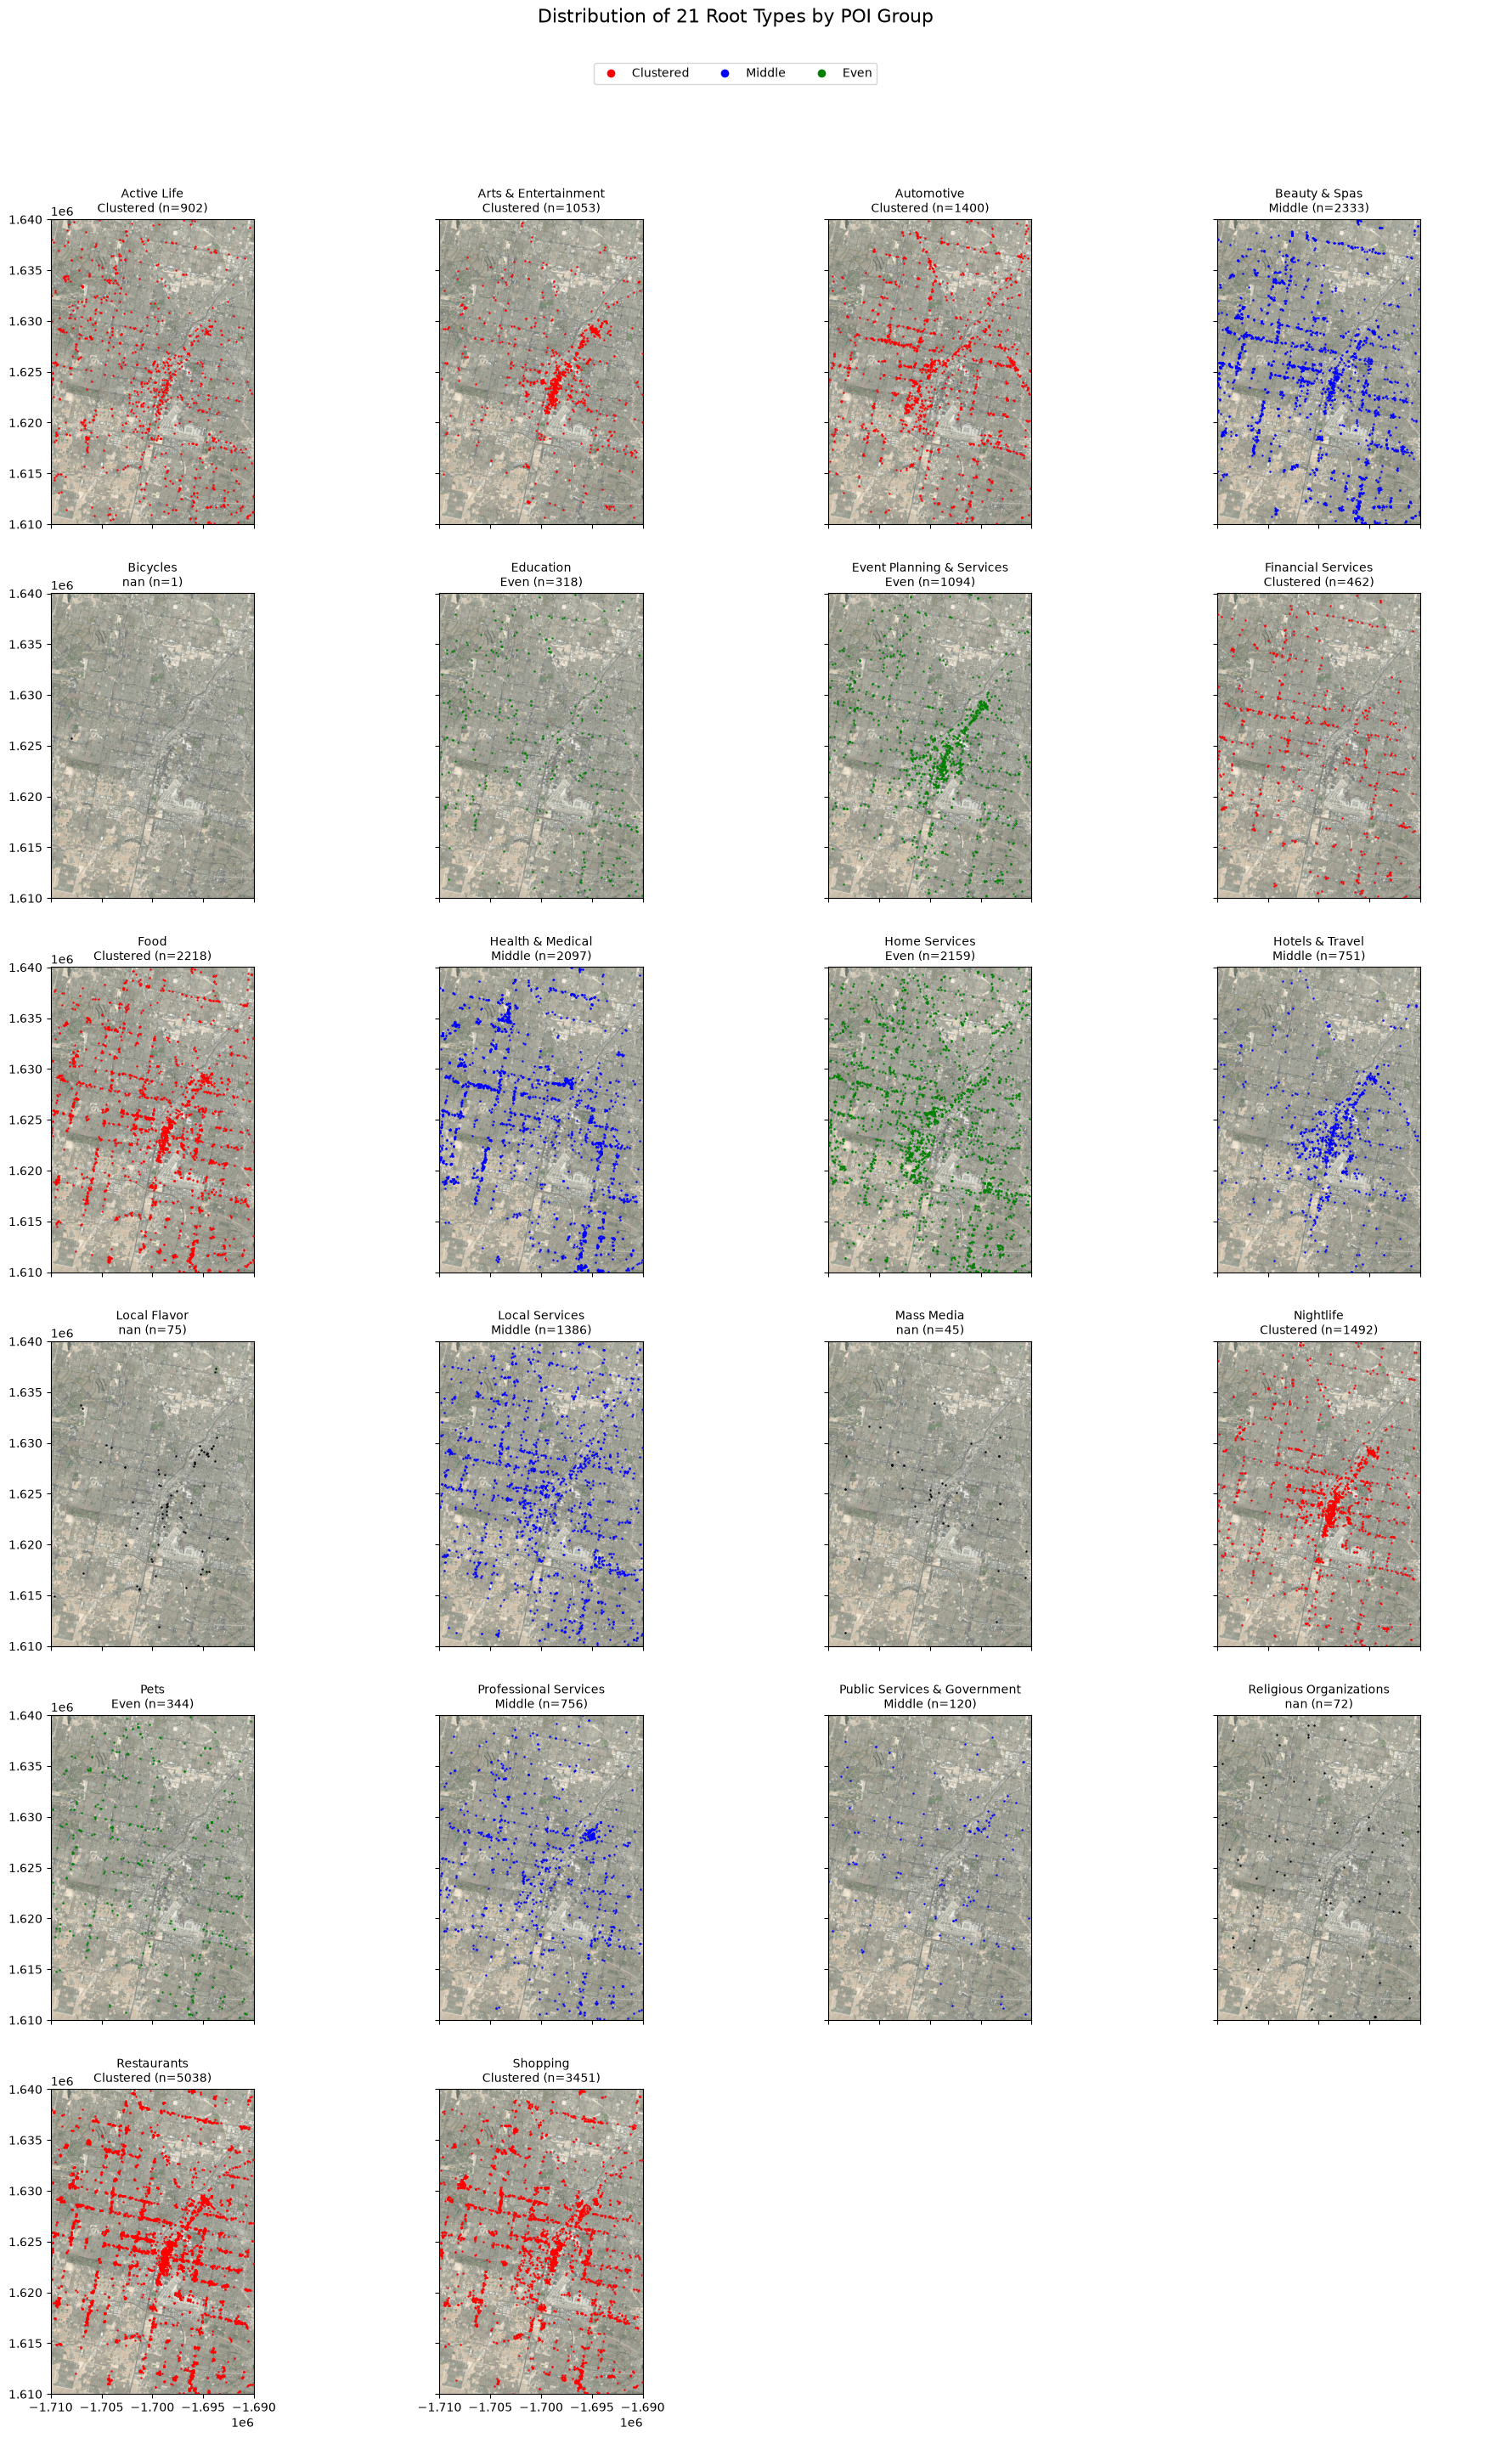

In [60]:
# 背景航空写真
img_path = Path("map_cache/las_vegas.png")
extent_path = Path("map_cache/las_vegas_extent.json")

img = Image.open(img_path)
with open(extent_path, "r", encoding="utf-8") as f:
    img_extent = json.load(f)["extent"]   # [xmin, xmax, ymin, ymax]

# -----------------------------
# 2. 全地点をDataFrame化
# -----------------------------
records = []

for pid, pt in pointset.pt_dict.items():
    # 各地点に含まれる root type を重複除去して取得
    roots = sorted({
        typeid2root[int(t)]
        for t in pt.features
        if int(t) in typeid2root
    })

    records.append({
        "point_id": pid,
        "x": pt.coord[0],
        "y": pt.coord[1],
        "features": tuple(pt.features),
        "root_ids": tuple(roots),
        "data_mode": getattr(pt, "data_mode", None),
    })

df_points = pd.DataFrame(records)

print("全地点数:", len(df_points))
display(df_points.head())

# -----------------------------
# 3. root id -> root name
#    root id は root type 自身の type id なので
#    poi_type.json から名前を引ける
# -----------------------------
all_root_ids = sorted({
    rid
    for roots in df_points["root_ids"]
    for rid in roots
})

root_name_map = {
    rid: poi_type.get(str(rid), f"root_{rid}")
    for rid in all_root_ids
}

root_df = pd.DataFrame({
    "root_id": all_root_ids,
    "root_name": [root_name_map[rid] for rid in all_root_ids]
}).sort_values("root_name")

display(root_df)

# -----------------------------
# 4. rootごとにexplodeして、
#    どの地点がどのrootに属するかの縦長形式へ
# -----------------------------
df_root_points = (
    df_points[["point_id", "x", "y", "root_ids"]]
    .explode("root_ids")
    .rename(columns={"root_ids": "root_id"})
    .dropna(subset=["root_id"])
    .copy()
)

df_root_points["root_id"] = df_root_points["root_id"].astype(int)
df_root_points["root_name"] = df_root_points["root_id"].map(root_name_map)

display(df_root_points.head())

# rootごとの件数
root_counts = (
    df_root_points.groupby(["root_id", "root_name"])
    .size()
    .reset_index(name="count")
    .sort_values("count", ascending=False)
)

display(root_counts)

name_to_group = {
    name: group
    for group, names in ROOT_GROUPS.items()
    for name in names
}

root_df["poi_group"] = root_df["root_name"].map(name_to_group)
display(root_df)

group_colors = {
    "Clustered": "red",
    "Middle": "blue",
    "Even": "green",
}

n_roots = len(root_df)
ncols = 4
nrows = int(np.ceil(n_roots / ncols))

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(4.6 * ncols, 4.8 * nrows),
    sharex=True,
    sharey=True,
    
)

axes = np.array(axes).reshape(-1)

xmin, xmax, ymin, ymax = img_extent

for ax, (_, row) in zip(axes, root_df.iterrows()):
    rid = row["root_id"]
    rname = row["root_name"]
    group = row["poi_group"]

    sub = df_root_points[df_root_points["root_id"] == rid]

    # 背景航空写真
    ax.imshow(
        img,
        extent=img_extent,
        origin="upper",
        alpha=0.7,
        zorder=0
    )

    # 全地点を薄灰色で背景表示（任意）
    ax.scatter(
        df_points["x"],
        df_points["y"],
        s=1,
        alpha=0.03,
        color="gray",
        linewidths=0,
        zorder=1
    )

    # 対象root地点をグループ色で描画
    ax.scatter(
        sub["x"],
        sub["y"],
        s=3,
        alpha=1,
        color=group_colors.get(group, "black"),
        linewidths=0,
        zorder=2
    )

    ax.set_title(
        f"{rname}\n{group} (n={len(sub)})",
        fontsize=10
    )
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_aspect("equal")

# 余った軸を消す
for ax in axes[n_roots:]:
    ax.axis("off")

fig.suptitle("Distribution of 21 Root Types by POI Group", fontsize=16, y=0.995)
fig.tight_layout()
from matplotlib.lines import Line2D

legend_handles = [
    Line2D([0], [0], marker='o', color='w',
           markerfacecolor=group_colors[g],
           markersize=8, label=g)
    for g in ["Clustered", "Middle", "Even"]
]

fig.legend(
    handles=legend_handles,
    loc="upper center",
    ncol=3,
    bbox_to_anchor=(0.5, 0.975)
)

# 上部にタイトルと凡例のための余白を確保
fig.tight_layout(
    rect=[0, 0, 1, 0.94],
    h_pad=2.5,
    w_pad=1.5
)

plt.show()